# Classificação — Wine Quality

Parte 2 do trabalho: **agrupar as notas em faixas de qualidade e prever a faixa** de
cada vinho a partir das variáveis físico-químicas.

A estrutura segue a da regressão (`regression.ipynb`): o mesmo split, o mesmo
pré-processamento (`src/preparacao.py`), validação cruzada e `GridSearchCV`. O que
muda é o alvo (faixas em vez de notas), as métricas e o tratamento do
desbalanceamento entre as classes.

Roteiro: criação das faixas → comparação de três esquemas de faixas → escolha do
balanceamento → ajuste de hiperparâmetros → avaliação no teste → análise dos erros
e das variáveis decisivas.

## 1. Setup

In [1]:
import sys

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, LabelEncoder
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# imbalanced-learn: SMOTE e um Pipeline que aplica o SMOTE só no treino
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Permite importar o módulo src/ a partir da pasta notebooks/
sys.path.append("..")
from src.preparacao import RANDOM_STATE, carregar_dados, dividir_treino_teste, criar_pipeline

# Cor dos gráficos
AZUL = "#2a78d6"

## 2. Dados e split treino/teste

O split é **o mesmo da regressão** (mesma função e mesma semente): os mesmos 4.253
vinhos no treino e 1.064 no teste. Ele continua estratificado pela `quality`.

As faixas são criadas **depois** do split. Isso não causa vazamento: transformar a
nota em faixa usa limites fixos, escolhidos por nós, e não aprende nada dos dados.

In [2]:
X, y = carregar_dados()
X_train, X_test, y_train, y_test = dividir_treino_teste(X, y)

print(f"Treino: {len(X_train)} vinhos | Teste: {len(X_test)} vinhos")

Treino: 4253 vinhos | Teste: 1064 vinhos


## 3. Criação das faixas de qualidade

Três esquemas, cada um respondendo a uma pergunta diferente:

| Esquema | Classes | Pergunta |
|---|---|---|
| **A** | baixa (3–4) / média (5–6) / alta (7–9) | o vinho é ruim, médio ou bom? |
| **B** | ruim (≤ 5) / bom (≥ 6) | o vinho vale a pena? |
| **C** | comum (≤ 6) / excelente (≥ 7) | o vinho é excelente? |

A função `pd.cut` faz a conversão: os `limites` definem intervalos fechados à
direita. Por exemplo, `[0, 4, 6, 10]` gera os intervalos (0, 4], (4, 6] e (6, 10],
ou seja, notas até 4, notas 5–6 e notas a partir de 7.

In [3]:
ESQUEMAS = {
    "A": {"limites": [0, 4, 6, 10], "classes": ["baixa", "media", "alta"]},
    "B": {"limites": [0, 5, 10], "classes": ["ruim", "bom"]},
    "C": {"limites": [0, 6, 10], "classes": ["comum", "excelente"]},
}


def criar_faixas(quality, esquema):
    """Converte as notas (quality) nas faixas do esquema."""
    return pd.cut(quality, bins=esquema["limites"], labels=esquema["classes"]).astype(str)

In [4]:
# Distribuição das classes no treino, em cada esquema
linhas = []
for nome, esquema in ESQUEMAS.items():
    contagem = criar_faixas(y_train, esquema).value_counts()
    for classe in esquema["classes"]:
        linhas.append({"esquema": nome, "classe": classe, "vinhos": contagem[classe],
                       "%": 100 * contagem[classe] / len(y_train)})

pd.DataFrame(linhas).set_index(["esquema", "classe"]).round(1)

vinhos     %
esquema classe                 
A       baixa         189   4.4
        media        3257  76.6
        alta          807  19.0
B       ruim         1590  37.4
        bom          2663  62.6
C       comum        3446  81.0
        excelente     807  19.0

**Observações:**

- **Esquema A:** fortemente desbalanceado. A classe "média" tem 77% dos vinhos, e a
  "baixa" só 4% (189 vinhos no treino, cerca de 47 no teste).
- **Esquema B:** o mais equilibrado (37% × 63%).
- **Esquema C:** desbalanceamento moderado (81% × 19%).

## 4. Validação cruzada e métricas

A validação cruzada usa `StratifiedKFold`: 5 folds embaralhados, com a mesma
proporção de cada classe em todos os folds. Sem isso, um fold poderia ficar quase
sem vinhos da classe rara.

**Por que não usar só a acurácia?** No esquema A, um modelo que responde sempre
"média" acerta 77% dos vinhos, sem nunca encontrar um vinho ruim ou bom. A acurácia
é dominada pela classe majoritária. Por isso:

- **F1 macro** (métrica principal, usada para escolher os hiperparâmetros): calcula o
  F1 de cada classe separadamente e tira a média simples, então a classe rara pesa
  tanto quanto a comum. O F1 de uma classe combina:
  - **precisão**: dos vinhos que o modelo pôs na classe, quantos eram mesmo dela?
  - **recall**: dos vinhos da classe, quantos o modelo encontrou?
- **Balanced accuracy**: média do % de acerto dentro de cada classe.
- **Acurácia**: % de acertos no total, mostrada para comparação.

In [5]:
# 5 folds estratificados, sempre os mesmos para todos os modelos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

METRICAS = {
    "F1 macro": "f1_macro",
    "Balanced acc.": "balanced_accuracy",
    "Acurácia": "accuracy",
}


def avaliar_cv(pipeline, alvo):
    """Roda a validação cruzada no treino e devolve a média de cada métrica."""
    resultado = cross_validate(pipeline, X_train, alvo, cv=cv, scoring=METRICAS, n_jobs=-1)
    return {nome: resultado[f"test_{nome}"].mean() for nome in METRICAS}

## 5. Comparação dos esquemas de faixas

Teste rápido com o mesmo modelo nos três esquemas: um Random Forest com
`class_weight="balanced"` (explicado na seção 6.2) e a configuração padrão. O
baseline (`DummyClassifier`) responde sempre a classe mais comum.

O F1 macro não é diretamente comparável entre esquemas com números de classes
diferentes (o baseline já começa em valores diferentes). Por isso a tabela mostra
também o **ganho sobre o baseline** de cada esquema.

In [6]:
linhas = {}
for nome, esquema in ESQUEMAS.items():
    alvo = criar_faixas(y_train, esquema)

    baseline = avaliar_cv(criar_pipeline(DummyClassifier(strategy="most_frequent")), alvo)
    floresta = avaliar_cv(criar_pipeline(RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE)), alvo)

    linhas[nome] = {
        "F1 macro baseline": baseline["F1 macro"],
        "F1 macro RF": floresta["F1 macro"],
        "ganho": floresta["F1 macro"] - baseline["F1 macro"],
        "Balanced acc. RF": floresta["Balanced acc."],
        "Acurácia baseline": baseline["Acurácia"],
        "Acurácia RF": floresta["Acurácia"],
    }

pd.DataFrame(linhas).T.round(3)

,F1 macro baseline,F1 macro RF,ganho,Balanced acc. RF,Acurácia baseline,Acurácia RF
A,0.289,0.549,0.260,0.547,0.766,0.767
B,0.385,0.748,0.363,0.750,0.626,0.762
C,0.448,0.729,0.282,0.737,0.810,0.828


**Observações:**

- **A acurácia engana no esquema A.** O baseline, que responde sempre "média", tem
  acurácia de 76,6%, praticamente igual à do Random Forest (76,7%). Pela acurácia, o
  modelo não seria melhor que um chute fixo. Pelo F1 macro, ele sobe de 0,29 para
  0,55, porque passa a encontrar vinhos das classes baixa e alta.
- **O esquema B é o mais fácil**: tem o maior F1 macro (0,75) e o maior ganho sobre
  o baseline (+0,36). São só duas classes, quase equilibradas.
- **O esquema C fica no meio** (F1 macro de 0,73).
- **O esquema A é o mais difícil** (F1 macro de 0,55), por ter três classes e uma
  delas muito pequena.

**Escolha: o esquema A segue como principal.** Ele é o mais informativo (separa
vinhos ruins, médios e bons, enquanto B e C respondem a uma pergunta só), é o tipo
de divisão sugerido no enunciado e ataca a principal limitação da regressão: a
dificuldade de identificar os vinhos extremos.

## 6. Esquema A: preparação

### 6.1 Codificação dos rótulos (LabelEncoder)

O `LabelEncoder` transforma os nomes das classes em números (0, 1, 2). Os modelos do
scikit-learn aceitam texto, mas codificar deixa explícito o que entra no modelo.

A numeração segue a **ordem alfabética** (alta = 0, baixa = 1, media = 2), não a
ordem de qualidade. Isso não afeta os modelos: para eles, os números são só nomes de
categorias, sem ordem. Nos gráficos e tabelas, as classes são mostradas na ordem
baixa → média → alta.

In [7]:
ESQUEMA = ESQUEMAS["A"]
ORDEM = ESQUEMA["classes"]   # ["baixa", "media", "alta"]

faixa_train = criar_faixas(y_train, ESQUEMA)
faixa_test = criar_faixas(y_test, ESQUEMA)

# O encoder aprende as classes no treino e aplica a mesma conversão no teste
encoder = LabelEncoder().fit(faixa_train)
y_train_cls = encoder.transform(faixa_train)
y_test_cls = encoder.transform(faixa_test)

# Códigos das classes na ordem baixa → média → alta (usado nos gráficos)
CODIGOS = encoder.transform(ORDEM)

dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

{'alta': np.int64(0), 'baixa': np.int64(1), 'media': np.int64(2)}

### 6.2 Balanceamento das classes

No treino há cerca de 3.250 vinhos "média" e só 189 "baixa". Sem tratamento, o modelo
aprende que errar a classe rara quase não afeta o resultado total e passa a
responder "média" quase sempre. Duas formas de corrigir:

- **`class_weight="balanced"`**: não mexe nos dados; faz o erro numa classe rara
  "custar mais" ao modelo, com peso proporcional à raridade (errar um vinho "baixa"
  pesa cerca de 17 vezes mais que errar um "média").
- **SMOTE (oversampling)**: cria vinhos sintéticos da classe rara, "no meio do
  caminho" entre um vinho dela e um vizinho parecido, até as classes ficarem do
  mesmo tamanho.

O SMOTE fica **dentro do pipeline** do `imbalanced-learn`: os vinhos sintéticos são
criados só com o treino de cada rodada da validação cruzada, nunca com os dados de
validação ou de teste. O *undersampling* (descartar vinhos da classe grande) não foi
testado: exigiria jogar fora cerca de 3.000 vinhos.

Abaixo, os três modelos com a configuração padrão em três versões: sem
balanceamento, com `class_weight` e com SMOTE.

In [8]:
def criar_pipeline_smote(modelo):
    """Pipeline com o SMOTE entre a padronização e o modelo."""
    etapas = criar_pipeline(modelo).steps[:-1]   # prep e scaler, sem o modelo
    return ImbPipeline(etapas + [
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", modelo),
    ])


# Cada modelo é criado por uma função, para receber o class_weight desejado
MODELOS = {
    "Regressão Logística": lambda peso: LogisticRegression(class_weight=peso, max_iter=2000),
    "Random Forest": lambda peso: RandomForestClassifier(class_weight=peso, random_state=RANDOM_STATE),
    "Gradient Boosting": lambda peso: HistGradientBoostingClassifier(class_weight=peso, random_state=RANDOM_STATE),
}

linhas = {}
for nome, criar_modelo in MODELOS.items():
    linhas[(nome, "sem balanceamento")] = avaliar_cv(criar_pipeline(criar_modelo(None)), y_train_cls)
    linhas[(nome, "class_weight")] = avaliar_cv(criar_pipeline(criar_modelo("balanced")), y_train_cls)
    linhas[(nome, "SMOTE")] = avaliar_cv(criar_pipeline_smote(criar_modelo(None)), y_train_cls)

resultados_balanceamento = pd.DataFrame(linhas).T
resultados_balanceamento.round(3)

F1 macro  Balanced acc.  Acurácia
Regressão Logística sem balanceamento     0.441          0.428     0.783
                    class_weight          0.450          0.610     0.542
                    SMOTE                 0.448          0.617     0.536
Random Forest       sem balanceamento     0.475          0.453     0.797
                    class_weight          0.549          0.547     0.767
                    SMOTE                 0.542          0.553     0.749
Gradient Boosting   sem balanceamento     0.496          0.472     0.790
                    class_weight          0.540          0.527     0.773
                    SMOTE                 0.539          0.531     0.764

**Observações:**

- **Sem balanceamento, os modelos quase só respondem "média".** A acurácia é alta
  (78–80%), mas a balanced accuracy fica entre 0,43 e 0,47, pouco acima do 0,33 de
  quem chuta sempre a mesma classe.
- **O `class_weight` melhora os modelos de árvore**: o F1 macro sobe de 0,48 para
  0,55 no Random Forest e de 0,50 para 0,54 no Gradient Boosting.
- **Na Regressão Logística, o efeito é diferente.** O F1 macro quase não muda
  (0,44 → 0,45), mas a balanced accuracy sobe de 0,43 para 0,61 e a acurácia cai
  para 0,54. O modelo passa a apontar as classes raras com frequência demais: acerta
  mais vinhos raros, mas erra muitos vinhos médios.
- **O SMOTE dá praticamente o mesmo resultado do `class_weight`** (diferenças de no
  máximo 0,007 no F1 macro).

**Escolha: `class_weight="balanced"`.** Os resultados são equivalentes aos do SMOTE,
e ele é mais simples: não cria dados sintéticos nem exige uma etapa a mais no
pipeline.

## 7. Ajuste de hiperparâmetros (GridSearchCV)

Mesmo procedimento da regressão, agora escolhendo a combinação de **maior F1 macro**.
Todos os modelos usam `class_weight="balanced"`, escolhido na seção 6.2.

In [9]:
def ajustar(modelo, grade):
    """Roda o GridSearchCV no pipeline do modelo e escolhe a combinação de maior F1 macro."""
    busca = GridSearchCV(
        criar_pipeline(modelo), grade, cv=cv, scoring=METRICAS,
        refit="F1 macro",   # métrica usada para escolher a melhor combinação
        n_jobs=-1,
    )
    busca.fit(X_train, y_train_cls)
    return busca


def resumo(busca):
    """Métricas de validação cruzada da melhor combinação encontrada."""
    i = busca.best_index_
    return {nome: busca.cv_results_[f"mean_test_{nome}"][i] for nome in METRICAS}

### 7.1 Regressão Logística

Apesar do nome, é um modelo de **classificação**: o equivalente linear do Ridge.
Ela calcula, para cada classe, uma soma ponderada das variáveis e escolhe a classe
com maior probabilidade.

- **`C`**: controla a penalidade nos coeficientes, mas ao contrário do `alpha` do
  Ridge: **`C` pequeno = penalidade forte**; `C` grande = penalidade fraca.
- **`prep__cauda__log`**: com ou sem log nas variáveis de cauda longa (na regressão,
  o log melhorou o modelo linear).

O tipo de padronização não é testado de novo: na regressão, ele não fez diferença.

In [10]:
# feature_names_out="one-to-one": o log mantém os nomes das colunas
LOG = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

grade_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "prep__cauda__log": ["passthrough", LOG],
}

busca_lr = ajustar(LogisticRegression(class_weight="balanced", max_iter=2000), grade_lr)
busca_lr.best_params_

{'model__C': 1,
 'prep__cauda__log': FunctionTransformer(feature_names_out='one-to-one', func=<ufunc 'log1p'>)}

In [11]:
# Todas as 10 combinações, da melhor para a pior
pd.DataFrame({
    "C": busca_lr.cv_results_["param_model__C"],
    "log": ["sem log" if l == "passthrough" else "com log"
            for l in busca_lr.cv_results_["param_prep__cauda__log"]],
    "F1 macro": busca_lr.cv_results_["mean_test_F1 macro"],
}).sort_values("F1 macro", ascending=False).round(4)

,C,log,F1 macro
5,1.00,com log,0.4669
7,10.00,com log,0.4667
9,100.00,com log,0.4665
3,0.10,com log,0.4650
1,0.01,com log,0.4624
2,0.10,sem log,0.4517
4,1.00,sem log,0.4504
8,100.00,sem log,0.4501
6,10.00,sem log,0.4500
0,0.01,sem log,0.4492


### 7.2 Random Forest

Os mesmos hiperparâmetros da regressão: número de árvores (`n_estimators`),
profundidade máxima (`max_depth`) e mínimo de vinhos por folha (`min_samples_leaf`).

In [12]:
grade_rf = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 3, 5],
}

busca_rf = ajustar(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE), grade_rf)
busca_rf.best_params_

{'model__max_depth': None,
 'model__min_samples_leaf': 3,
 'model__n_estimators': 500}

### 7.3 Gradient Boosting

Os mesmos hiperparâmetros da regressão: `learning_rate`, `max_iter` (número de
árvores) e `max_depth`.

In [13]:
grade_gb = {
    "model__learning_rate": [0.01, 0.03, 0.1],
    "model__max_iter": [200, 500, 1000],
    "model__max_depth": [3, 6, None],
}

busca_gb = ajustar(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), grade_gb)
busca_gb.best_params_

{'model__learning_rate': 0.01,
 'model__max_depth': None,
 'model__max_iter': 500}

### 7.4 Antes × depois do ajuste

O "antes" é a versão com `class_weight` e a configuração padrão (seção 6.2).

In [14]:
buscas = {"Regressão Logística": busca_lr, "Random Forest": busca_rf, "Gradient Boosting": busca_gb}

comparacao = pd.DataFrame({
    "F1 macro padrão": [resultados_balanceamento.loc[(nome, "class_weight"), "F1 macro"] for nome in buscas],
    "F1 macro ajustado": [resumo(b)["F1 macro"] for b in buscas.values()],
}, index=list(buscas))
comparacao["melhora"] = comparacao["F1 macro ajustado"] - comparacao["F1 macro padrão"]

comparacao.round(4)

,F1 macro padrão,F1 macro ajustado,melhora
Regressão Logística,0.4504,0.4669,0.0165
Random Forest,0.5492,0.5603,0.0111
Gradient Boosting,0.5401,0.5563,0.0162


**Observações:**

- **O ajuste melhorou o F1 macro entre 0,011 e 0,017.** É um ganho pequeno, mas
  maior que o da regressão.
- **Regressão Logística:** como na regressão, **o log foi o que mais ajudou**: todas
  as combinações com log ficam à frente das sem log. O `C` quase não faz diferença.
- **Random Forest:** a melhor combinação usa `min_samples_leaf` = 3 (o padrão é 1).
  Folhas um pouco maiores impedem as árvores de decorar vinhos isolados, o que
  importa numa classe com só 189 exemplos.
- **Gradient Boosting:** a melhor combinação aprende devagar (`learning_rate` = 0,01)
  com muitas árvores (500). O número de árvores ficou no meio da grade, mas o
  `learning_rate` ficou na ponta. Testar valores menores (com ainda mais árvores)
  seria um próximo passo possível, mas o ganho total do ajuste já foi pequeno.

## 8. Avaliação no conjunto de teste

Os modelos ajustados são avaliados nos vinhos do teste, que não foram usados em
nenhuma decisão até aqui.

In [15]:
modelos_finais = {
    "Baseline (classe mais comum)": criar_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train_cls),
    "Regressão Logística": busca_lr.best_estimator_,
    "Random Forest": busca_rf.best_estimator_,
    "Gradient Boosting": busca_gb.best_estimator_,
}

previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos_finais.items()}

resultados_teste = pd.DataFrame({
    nome: {
        "F1 macro": f1_score(y_test_cls, y_pred, average="macro"),
        "Balanced acc.": balanced_accuracy_score(y_test_cls, y_pred),
        "Acurácia": accuracy_score(y_test_cls, y_pred),
    }
    for nome, y_pred in previsoes.items()
}).T

resultados_teste.round(3)

,F1 macro,Balanced acc.,Acurácia
Baseline (classe mais comum),0.289,0.333,0.766
Regressão Logística,0.477,0.685,0.558
Random Forest,0.603,0.658,0.749
Gradient Boosting,0.589,0.634,0.741


In [16]:
# Melhor modelo escolhido pela validação cruzada (não pelo teste)
melhor = max(buscas, key=lambda nome: resumo(buscas[nome])["F1 macro"])
print(f"Melhor modelo na validação cruzada: {melhor}\n")

# Precisão, recall e F1 de cada classe, no teste
print(classification_report(y_test_cls, previsoes[melhor], labels=CODIGOS, target_names=ORDEM))

Melhor modelo na validação cruzada: Random Forest

              precision    recall  f1-score   support

       baixa       0.32      0.49      0.39        47
       media       0.89      0.77      0.83       815
        alta       0.50      0.71      0.59       202

    accuracy                           0.75      1064
   macro avg       0.57      0.66      0.60      1064
weighted avg       0.79      0.75      0.76      1064



**Observações:**

- **O Random Forest foi o melhor modelo**, com F1 macro de 0,60 contra 0,29 do
  baseline. O Gradient Boosting ficou muito perto (0,59), e a Regressão Logística,
  atrás (0,48).
- O F1 macro no teste (0,60) ficou acima do da validação cruzada (0,56). Com só 47
  vinhos da classe baixa no teste, poucos acertos a mais já mudam bastante o F1
  dessa classe. O desempenho esperado em vinhos novos fica entre esses dois valores.
- **A Regressão Logística tem a maior balanced accuracy (0,69), mas a menor
  acurácia (0,56).** Ela encontra mais vinhos das classes raras, mas com muitos
  alarmes falsos (seção 9.1). É por isso que o F1 macro foi escolhido como métrica
  principal: ele cobra também a precisão, enquanto a balanced accuracy só olha o
  recall.
- **Por classe (Random Forest):**
  - **média:** F1 de 0,83;
  - **alta:** F1 de 0,59, encontrando 71% dos vinhos dela;
  - **baixa:** F1 de 0,39, a mais difícil. O modelo encontra metade dos vinhos baixos
    (recall de 0,49), mas, dos 71 vinhos que ele chamou de "baixa", só 23 eram
    mesmo (precisão de 0,32).

## 9. Análise dos erros

### 9.1 Matrizes de confusão

Cada linha é a classe **real** e cada coluna, a classe **prevista**. Os valores são
a porcentagem dos vinhos de cada classe real: a diagonal é o acerto (recall) de cada
classe, e fora dela estão as confusões.

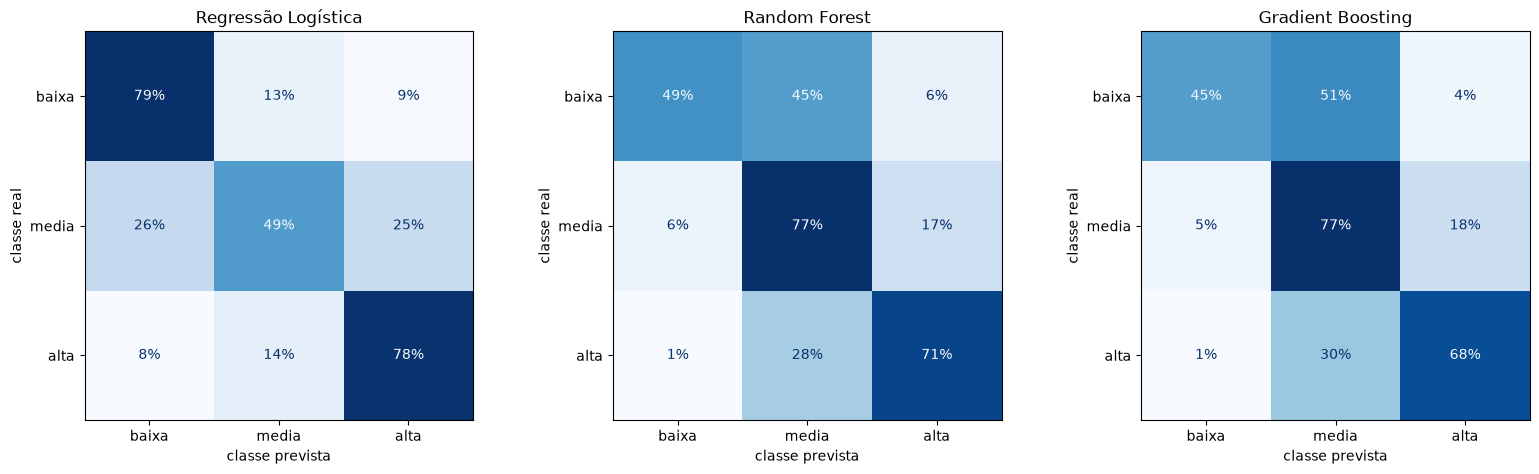

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, nome in zip(axes, buscas):
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls, previsoes[nome], labels=CODIGOS, display_labels=ORDEM,
        normalize="true",      # porcentagem por classe real (cada linha soma 100%)
        values_format=".0%", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("classe prevista")
    ax.set_ylabel("classe real")

plt.tight_layout()
plt.show()

In [18]:
# A mesma matriz do melhor modelo, em número de vinhos
pd.crosstab(
    pd.Categorical(encoder.inverse_transform(y_test_cls), categories=ORDEM),
    pd.Categorical(encoder.inverse_transform(previsoes[melhor]), categories=ORDEM),
    rownames=["real"], colnames=["prevista"], dropna=False,
)

prevista,baixa,media,alta
real,,,
baixa,23,21,3
media,46,630,139
alta,2,56,144


**Observações:**

- **As confusões acontecem quase só entre faixas vizinhas.** No Random Forest, só 5
  vinhos foram confundidos entre baixa e alta, as faixas opostas. O modelo "percebe"
  a ordem das faixas mesmo sem receber essa informação.
- **A maior confusão em número de vinhos é "média" prevista como "alta"** (139
  vinhos, 17% dos médios). No sentido contrário, 28% dos vinhos altos foram previstos
  como "média".
- **A classe baixa é a mais difícil**: quase metade (45%) dos vinhos baixos foi
  prevista como "média". São poucos exemplos para aprender.
- **A Regressão Logística erra de outro jeito**: encontra cerca de 80% dos vinhos
  baixos e altos, mas classifica metade dos médios como baixa ou alta. Se o objetivo
  fosse não deixar escapar nenhum vinho ruim, mesmo com alarmes falsos, ela poderia
  ser a escolha certa. A melhor métrica depende do uso do modelo.

### 9.2 Acerto por nota original

Dentro de cada faixa há notas diferentes (a faixa "média" junta as notas 5 e 6).
A tabela mostra o % de acerto do melhor modelo para cada nota original, para ver se
os erros se concentram perto das fronteiras entre as faixas.

In [19]:
acerto_por_nota = (
    pd.DataFrame({"quality": y_test.values, "acertou": previsoes[melhor] == y_test_cls})
    .groupby("quality")["acertou"]
    .agg(**{"acerto (%)": "mean", "vinhos no teste": "size"})
)
acerto_por_nota["acerto (%)"] *= 100
acerto_por_nota["faixa"] = criar_faixas(acerto_por_nota.index.to_series(), ESQUEMA).values

acerto_por_nota.round(1)

,acerto (%),vinhos no teste,faixa
quality,,,
3,33.3,6,baixa
4,51.2,41,baixa
5,87.2,351,media
6,69.8,464,media
7,71.3,171,alta
8,73.3,30,alta
9,0.0,1,alta


In [20]:
# Para onde vão os vinhos de cada nota: nota original × faixa prevista
pd.crosstab(
    y_test.values,
    pd.Categorical(encoder.inverse_transform(previsoes[melhor]), categories=ORDEM),
    rownames=["quality"], colnames=["faixa prevista"], dropna=False,
)

faixa prevista,baixa,media,alta
quality,,,
3,2,4,0
4,21,17,3
5,31,306,14
6,15,324,125
7,0,49,122
8,2,6,22
9,0,1,0


**Observações:**

- **Os erros se concentram nas notas da fronteira entre as faixas.**
  - **nota 6** (vizinha da faixa alta): 70% de acerto. Dos 139 vinhos médios previstos
    como "alta", 125 são de nota 6.
  - **nota 5** (longe dessa fronteira): 87% de acerto. Os erros dela vão para "baixa".
  - **nota 4** (vizinha da faixa média): 51% de acerto.
- A diferença química entre um vinho 6 e um 7 é sutil, e a nota é subjetiva:
  degustadores diferentes poderiam dar 6 ou 7 ao mesmo vinho. A regressão já mostrava
  isso, com erro médio de cerca de meio ponto. Quando a fronteira passa entre duas
  notas vizinhas, esses vinhos ficam na zona de dúvida.
- As notas 3 e 9 têm 6 e 1 vinhos no teste, poucos para conclusões.

## 10. Variáveis decisivas

*Permutation importance* (a mesma técnica da regressão): embaralha uma coluna no
teste e mede quanto o **F1 macro** piora. Aplicada ao melhor modelo e à Regressão
Logística, para comparar um modelo de árvore com o linear.

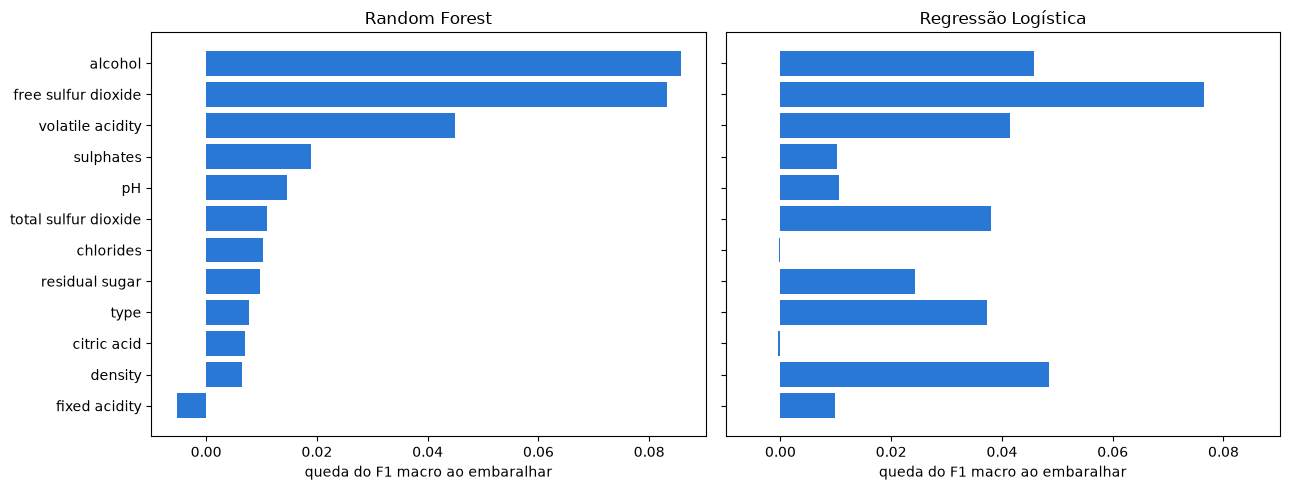

,Random Forest,Regressão Logística
alcohol,0.0857,0.0458
free sulfur dioxide,0.0833,0.0765
volatile acidity,0.0450,0.0414
sulphates,0.0189,0.0102
pH,0.0145,0.0106
total sulfur dioxide,0.0111,0.0381
chlorides,0.0103,-0.0003
residual sugar,0.0097,0.0243
type,0.0077,0.0374
citric acid,0.0070,-0.0005


In [21]:
def importancia(modelo):
    """Queda média do F1 macro no teste ao embaralhar cada coluna (10 repetições)."""
    resultado = permutation_importance(
        modelo, X_test, y_test_cls, scoring="f1_macro",
        n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
    )
    return pd.Series(resultado.importances_mean, index=X_test.columns)


comparados = [melhor, "Regressão Logística"] if melhor != "Regressão Logística" else [melhor, "Random Forest"]
importancias = pd.DataFrame({nome: importancia(modelos_finais[nome]) for nome in comparados}).sort_values(comparados[0])

# Mesma escala nos dois eixos, para comparar os modelos
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, sharex=True)

for ax, nome in zip(axes, importancias.columns):
    ax.barh(importancias.index, importancias[nome], color=AZUL)
    ax.set_title(nome)
    ax.set_xlabel("queda do F1 macro ao embaralhar")

plt.tight_layout()
plt.show()

importancias.sort_values(comparados[0], ascending=False).round(4)

**Observações:**

- **No Random Forest, as três variáveis decisivas são `alcohol`, `free sulfur
  dioxide` e `volatile acidity`**, as mesmas três da regressão. A diferença é que
  aqui o `free sulfur dioxide` quase empata com o `alcohol`, enquanto na regressão o
  `alcohol` ficava bem à frente.
- **A Regressão Logística distribui a importância por mais variáveis** (`density`,
  `total sulfur dioxide`, `type`). Como o Ridge na regressão, o modelo linear combina
  variáveis correlacionadas (`density` com `alcohol` e açúcar) para compensar o que
  não consegue capturar sozinho.
- Valores próximos de zero ou negativos (`fixed acidity` no Random Forest) indicam
  que embaralhar a variável não piora o modelo: ela não contribui.

## 11. Conclusões

1. **O esquema de faixas escolhido foi o A** (baixa 3–4 / média 5–6 / alta 7–9). Os
   esquemas de duas classes são mais fáceis (F1 macro de 0,73–0,75), mas respondem a
   uma pergunta só. O A separa os três níveis de qualidade.

2. **O balanceamento é necessário.** Sem ele, os modelos quase só respondem "média".
   O `class_weight` e o SMOTE tiveram resultados equivalentes, e o `class_weight` foi
   escolhido por ser mais simples.

3. **O Random Forest foi o melhor modelo**, com F1 macro de 0,60 no teste (o baseline
   tem 0,29). O Gradient Boosting empatou na prática. A Regressão Logística teve F1
   menor, mas encontra mais vinhos das classes raras, com muitos alarmes falsos.
   Qual modelo é "melhor" depende do custo de cada tipo de erro.

4. **As confusões acontecem entre faixas vizinhas**, concentradas nas notas de
   fronteira: vinhos de nota 6 previstos como "alta" e de nota 4 previstos como
   "média". A classe baixa é a mais difícil (F1 de 0,39), por ter poucos exemplos.

5. **As variáveis decisivas são `alcohol`, `free sulfur dioxide` e `volatile
   acidity`**, as mesmas três da regressão.

6. **Comparação com a Parte 1:** na regressão, as previsões ficavam presas entre 5 e
   7, e os vinhos extremos não eram identificados. Na classificação com
   balanceamento, o modelo encontra 71% dos vinhos de qualidade alta e cerca de
   metade dos de qualidade baixa. O agrupamento em faixas, junto com o
   balanceamento, resolve em parte essa limitação.